In [2]:
import os, sys
from pathlib import Path

here = Path.cwd()
PROJECT_DIR = here.parent if here.name == "notebooks" else here   # the folder with make_submission.py
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))                              # so "import freight_lib" works

print("Working folder:", PROJECT_DIR)
for name in ["freight_lib.py", "make_submission.py", "score.py", "data"]:
    print(f"{name:20s}", "found" if (PROJECT_DIR / name).exists() else "MISSING")
print("CSV files:", sorted(p.name for p in (PROJECT_DIR / "data").glob("*.csv")))

import numpy, pandas, sklearn, lightgbm, matplotlib
print("Libraries OK")

Working folder: C:\Users\Nouman\Documents\freight-rate-challenge
freight_lib.py       found
make_submission.py   found
score.py             found
data                 found
CSV files: ['december-chart-inputs.csv', 'train-test.csv', 'validation-predictions-template.csv', 'validation.csv']
Libraries OK


In [3]:
%run make_submission.py --data-dir data --out-dir .

C:\Users\Nouman\Documents\freight-rate-challenge\freight_lib.py:61: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  typical = rpm.groupby([df["equipment"], bins]).transform("median")


Training on 47,323 clean rows (677 dropped).
Wrote validation_predictions.csv and december_chart_inputs.csv to .


In [4]:
%run score.py --predictions validation_predictions.csv --december-predictions december_chart_inputs.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.


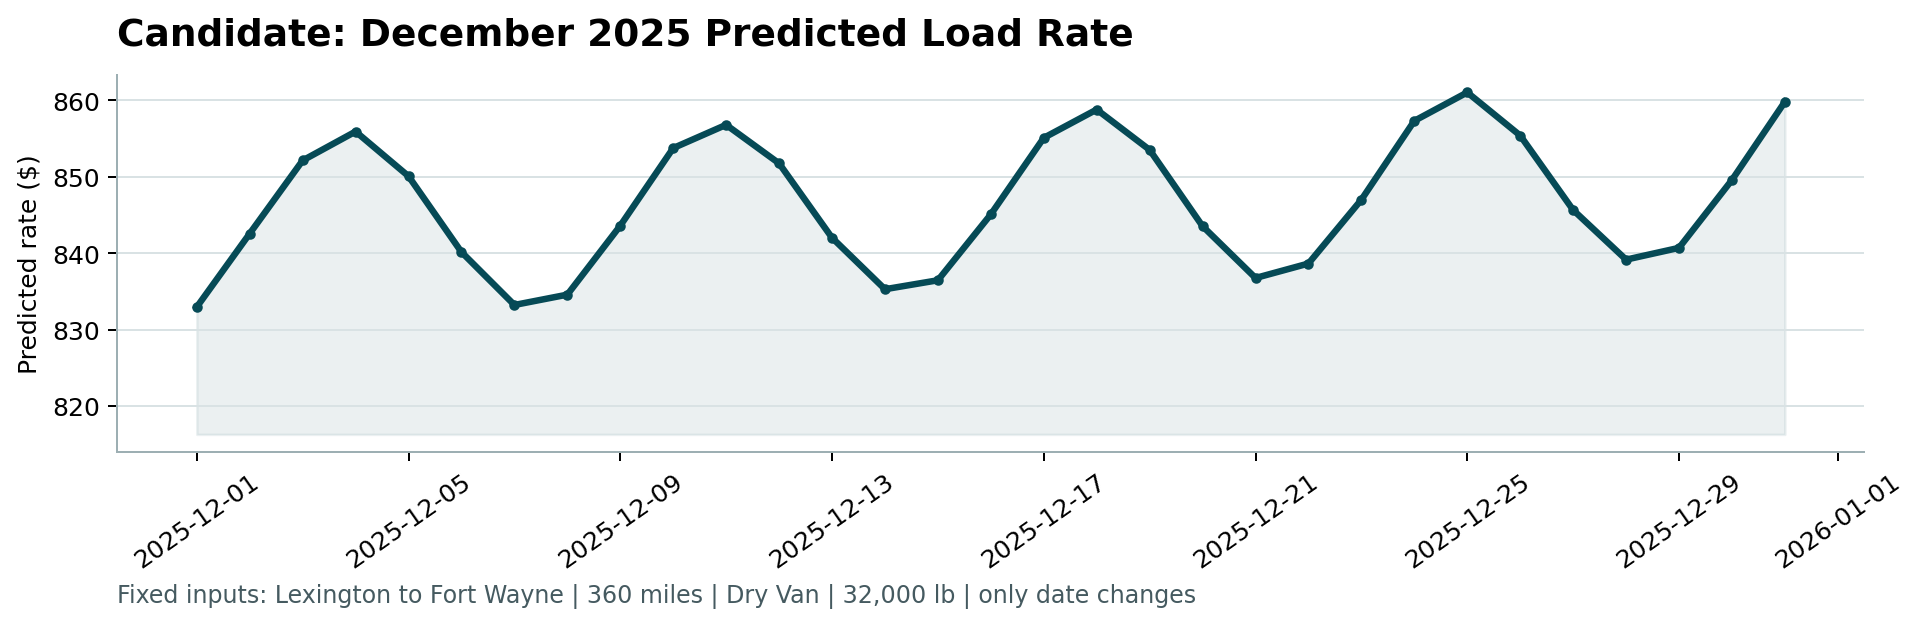

In [5]:
from IPython.display import Image
Image("scorer_results/candidate_december.png")